# **Overview**


Home Advantage in Football — Bias or Real?

This project investigates whether the well-known “home advantage” in football is a genuine effect of playing at home before a supportive crowd, or whether it is largely explained by differences in team strength.
A Decision Tree Classifier is a supervised machine learning model that predicts a category by asking a series of yes/no questions about the data. It is structured like a flowchart: starting from a single top node, the data is repeatedly split into branches until a final prediction is reached.
is trained to predict the outcome of a match, and the model’s feature importances are analysed to determine which factors most influence the result.

The dataset consists of 50,000 football matches drawn from several major leagues (English Premier League, La Liga, Serie A, and Bundesliga, among others). Each record describes the conditions of a single match, including:
Team strength: Elo ratings for the home and away teams, and their difference.
Crowd conditions: stadium capacity, attendance percentage, crowd size, and whether fans were present (including empty “ghost games”).
Travel factors: the away team’s travel distance, time zones crossed, and whether the fixture is a local derby.
Match context: venue familiarity and referee susceptibility to crowd pressure.
The target variable is the match result, classified as home win, draw, or away win.


# **(1) Import libraries, load dataset**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings("ignore", category=FutureWarning) # to stop getting warnings before figures

In [2]:
import os
import kagglehub

# Download the dataset (cached after the first run)
path = kagglehub.dataset_download("sergionefedov/home-advantage-in-football-bias-or-real")

# Show every file in the dataset
for root, dirs, files in os.walk(path):
    for f in files:
        print(os.path.relpath(os.path.join(root, f), path))

# Load the first CSV found
csv_files = [os.path.join(root, f)
             for root, dirs, files in os.walk(path)
             for f in files if f.endswith(".csv")]

# Pick the matches file by name, not by position
matches_file = [f for f in csv_files if "home_advantage_matches" in os.path.basename(f)][0]
df = pd.read_csv(matches_file)

print("\nLoaded:", os.path.basename(matches_file))
print("Shape:", df.shape) # should be (50000, 25)
df.head()

data_dictionary_home_advantage.csv
home_advantage_matches.csv

Loaded: home_advantage_matches.csv
Shape: (50000, 25)


,match_id,league,elo_home,elo_away,elo_diff,crowd_present,stadium_capacity,attendance_pct,crowd_size,travel_distance_km,...,fouls_away,yellow_home,yellow_away,red_home,red_away,goals_home,goals_away,home_goal_diff,home_result,home_points
0,MCH000000,Serie_A,1255,1507,-252,1,46200,0.557,25700,380.0,...,11,0,3,0,0,1,1,0,draw,1
1,MCH000001,Serie_A,1535,1500,35,1,27400,0.869,23800,420.0,...,14,1,1,0,0,4,2,2,home_win,3
2,MCH000002,Primeira,1736,1370,366,0,61800,0.000,0,16.5,...,13,4,1,0,0,0,2,-2,away_win,0
3,MCH000003,Eredivisie,1484,1476,8,1,30100,0.820,24700,110.0,...,13,2,2,0,0,0,0,0,draw,1
4,MCH000004,EPL,1407,1540,-133,1,55000,0.748,41100,300.0,...,16,1,1,0,0,2,0,2,home_win,3


# **(2) Apply EDA**.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   match_id                     50000 non-null  str    
 1   league                       50000 non-null  str    
 2   elo_home                     50000 non-null  int64  
 3   elo_away                     50000 non-null  int64  
 4   elo_diff                     50000 non-null  int64  
 5   crowd_present                50000 non-null  int64  
 6   stadium_capacity             50000 non-null  int64  
 7   attendance_pct               50000 non-null  float64
 8   crowd_size                   50000 non-null  int64  
 9   travel_distance_km           50000 non-null  float64
 10  timezones_crossed            50000 non-null  int64  
 11  is_derby                     50000 non-null  int64  
 12  venue_familiarity            50000 non-null  float64
 13  referee_bias_susceptibility

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
elo_home,50000.0,1500.61,119.50,1200.0,1419.00,1500.00,1581.00,1900.0
elo_away,50000.0,1499.65,118.82,1200.0,1419.00,1499.00,1580.00,1900.0
elo_diff,50000.0,0.96,168.54,-667.0,-113.00,0.00,116.00,675.0
crowd_present,50000.0,0.80,0.40,0.0,1.00,1.00,1.00,1.0
stadium_capacity,50000.0,38208.71,17190.71,8000.0,25700.00,38000.00,50100.00,90000.0
attendance_pct,50000.0,0.60,0.33,0.0,0.50,0.72,0.84,1.0
crowd_size,50000.0,22977.26,17125.61,0.0,7500.00,22900.00,35100.00,86300.0
travel_distance_km,50000.0,338.02,261.06,0.0,150.00,280.00,470.00,2390.0
timezones_crossed,50000.0,0.08,0.27,0.0,0.00,0.00,0.00,2.0
is_derby,50000.0,0.06,0.24,0.0,0.00,0.00,0.00,1.0


**Observations**
- 50,000 rows (one per match) and 25 columns.
- 23 columns are numeric. Only `match_id`, `league` and `home_result` are text.
- `elo_diff` is centred around 0 (mean ≈ 1), so home and away teams are evenly matched in strength on average.
- Several columns are **binary flags** (0/1): `crowd_present`, `is_derby`, `red_home`, `red_away`.

# 2.2 Identify features and target variable
Target variable: home_result, the match outcome from the home team's view (home_win, draw, away_win).

Columns fall into four groups. This matters because some columns are only known after the match. Using them would let the model "cheat" (data leakage).

In [5]:
target = "home_result"

pre_match_features = ["league", "elo_home", "elo_away", "elo_diff", "crowd_present",
                      "stadium_capacity", "attendance_pct", "crowd_size",
                      "travel_distance_km", "timezones_crossed", "is_derby",
                      "venue_familiarity", "referee_bias_susceptibility"]
in_match_stats = ["fouls_home", "fouls_away", "yellow_home", "yellow_away", "red_home", "red_away"]
leakage_cols   = ["goals_home", "goals_away", "home_goal_diff", "home_points"]

print("Target:", target)
print("Number of pre-match features:", len(pre_match_features))

Target: home_result
Number of pre-match features: 13


In [6]:
# Missing values and duplicates
missing = df.isna().sum()
print("Total missing values:", missing.sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate match_id:", df["match_id"].duplicated().sum())

Total missing values: 0
Duplicate rows: 0
Duplicate match_id: 0



**Observations:** there are no missing values and no duplicates, so no imputation or row removal is needed in preprocessing.

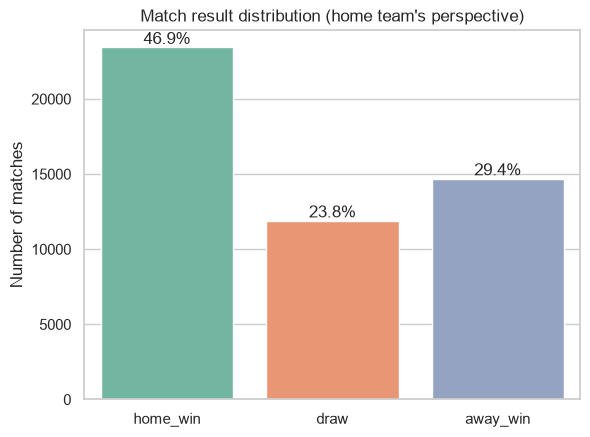

home_result
home_win    0.469
away_win    0.294
draw        0.238
Name: proportion, dtype: float64

In [7]:
# Target distribution (count plot)
order = ["home_win", "draw", "away_win"]
ax = sns.countplot(data=df, x=target, order=order, palette="Set2")
for p in ax.patches:
    ax.annotate(f"{p.get_height()/len(df):.1%}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Match result distribution (home team's perspective)")
ax.set_xlabel(""); ax.set_ylabel("Number of matches")
plt.show()

df[target].value_counts(normalize=True).round(3)

**Observations**

Home teams win ≈47% of matches, versus ≈29% away wins. This is the home advantage effect.
The classes are imbalanced (draws are only ≈24%). Accuracy alone can mislead, so we should also report precision, recall and F1 per class.
Baseline: always predicting home_win gives ≈47% accuracy. Our model must beat this.

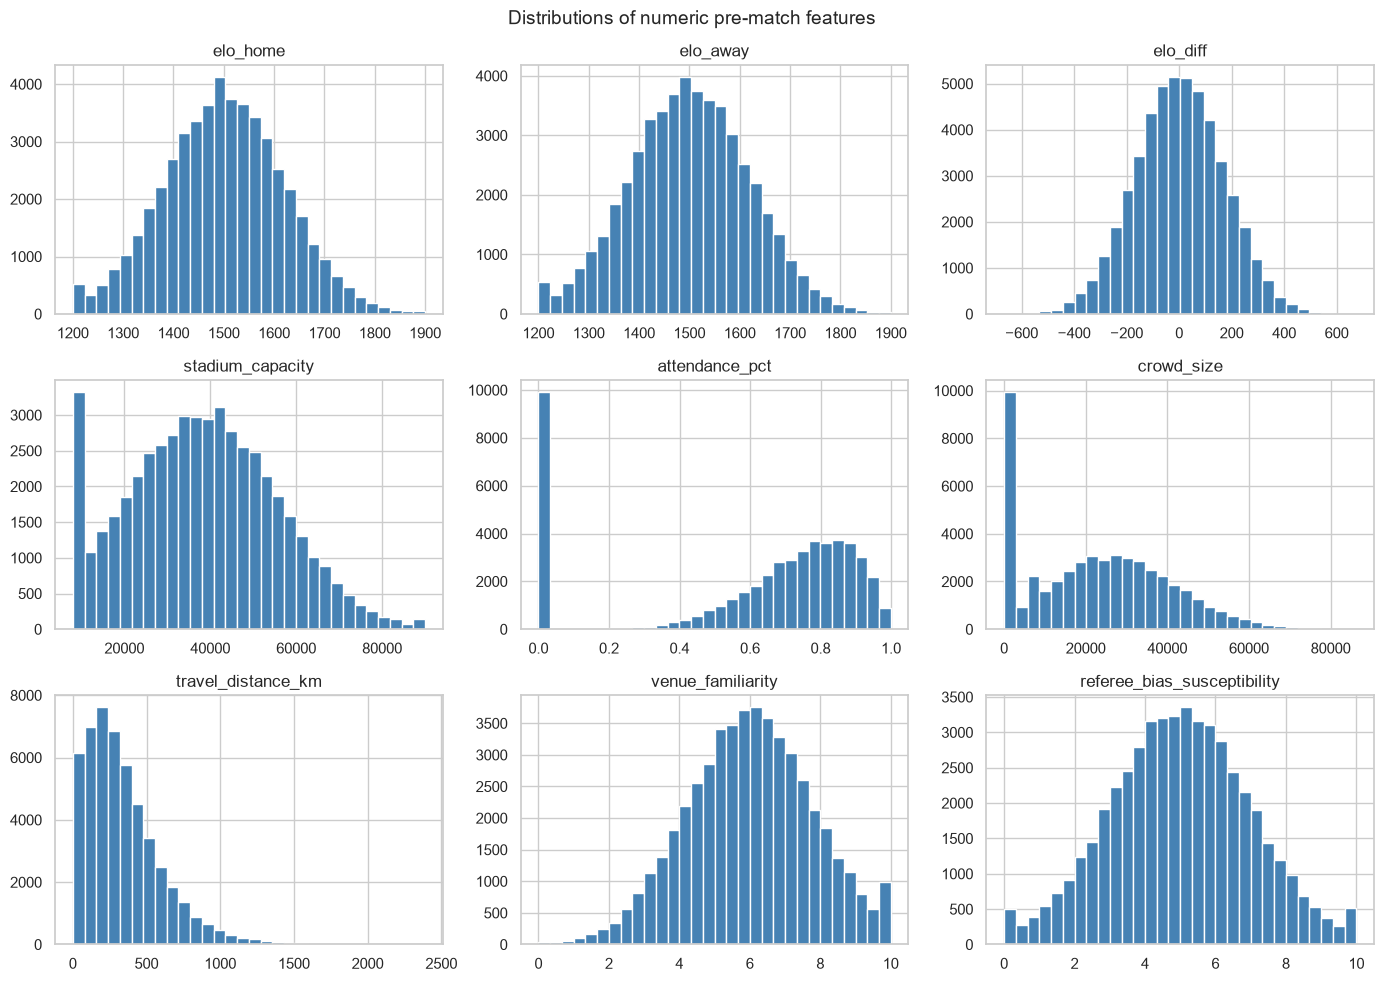

In [8]:
# Distributions of numeric features (histograms)
num_cols = ["elo_home", "elo_away", "elo_diff", "stadium_capacity", "attendance_pct",
            "crowd_size", "travel_distance_km", "venue_familiarity", "referee_bias_susceptibility"]

df[num_cols].hist(bins=30, figsize=(14, 10), color="steelblue", edgecolor="white")
plt.suptitle("Distributions of numeric pre-match features", fontsize=14)
plt.tight_layout()
plt.show()

**Observations**
- `elo_home` and `elo_away` are spread between 1200 and 1900. `elo_diff` looks roughly normal and centred at 0.
- `attendance_pct` and `crowd_size` have a big spike at **0**: these are matches played **without a crowd** (`crowd_present = 0`, about 20% of matches).
- `travel_distance_km` is **right-skewed**: most trips are short, with a long tail up to ~2,400 km.
- Feature scales differ a lot (0–10 vs 0–90,000). A **Decision Tree does not need feature scaling** because it splits on one feature at a time using thresholds.

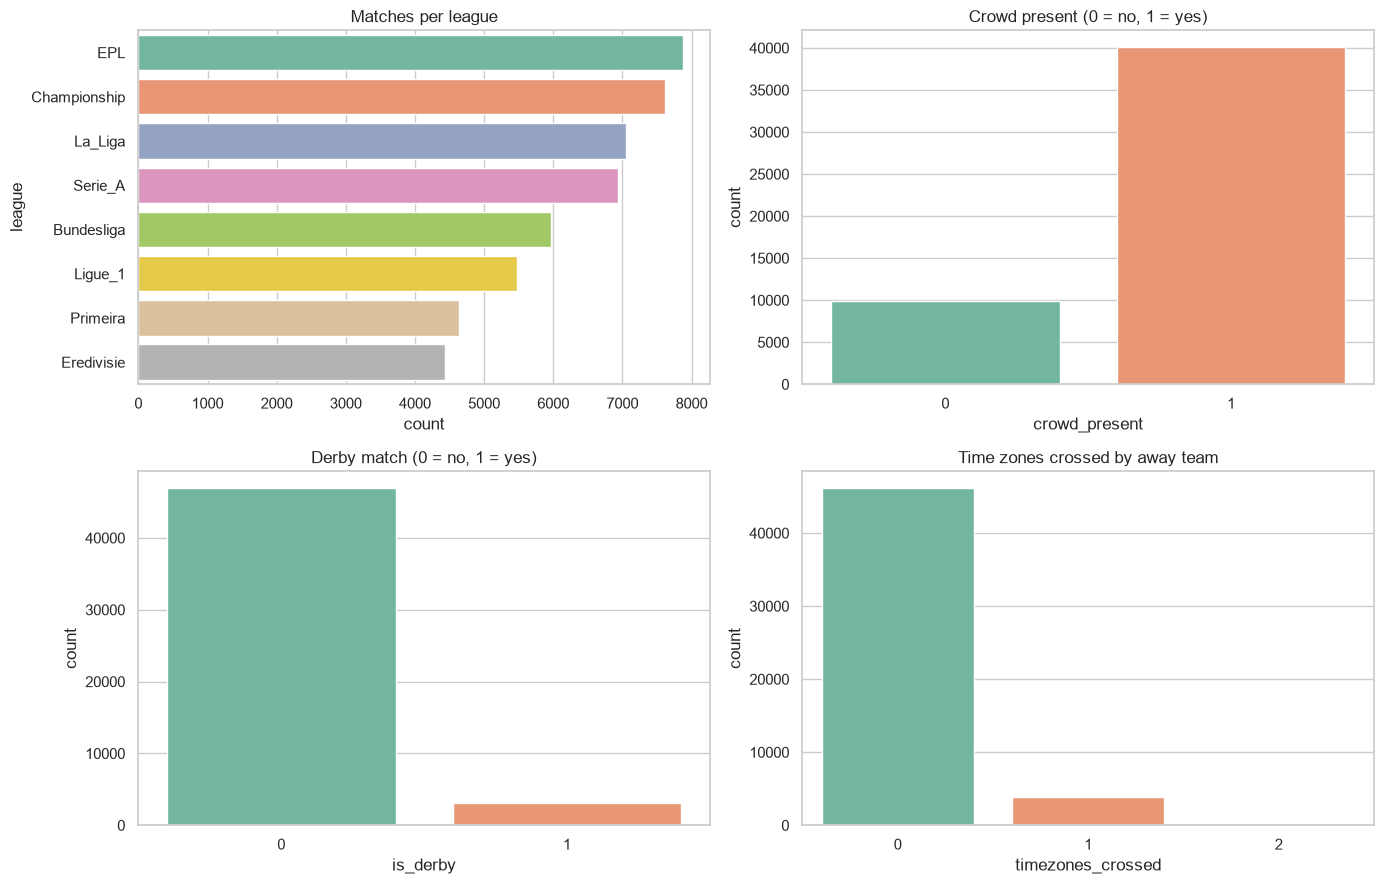

In [9]:
# Categorical and binary features (count plots)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.countplot(data=df, y="league", order=df["league"].value_counts().index, ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Matches per league")

sns.countplot(data=df, x="crowd_present", ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Crowd present (0 = no, 1 = yes)")

sns.countplot(data=df, x="is_derby", ax=axes[1, 0], palette="Set2")
axes[1, 0].set_title("Derby match (0 = no, 1 = yes)")

sns.countplot(data=df, x="timezones_crossed", ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("Time zones crossed by away team")

plt.tight_layout()
plt.show()

**Observations**
- 8 leagues, all well represented (EPL has the most matches, Eredivisie the fewest).
- ~80% of matches had a crowd and only ~6% are derbies.
- Almost all away teams cross **0** time zones. Only ~3,900 matches cross 1, and just 2 matches cross 2 (too few to draw conclusions).
- `league` is text, so it will need **encoding** in preprocessing.

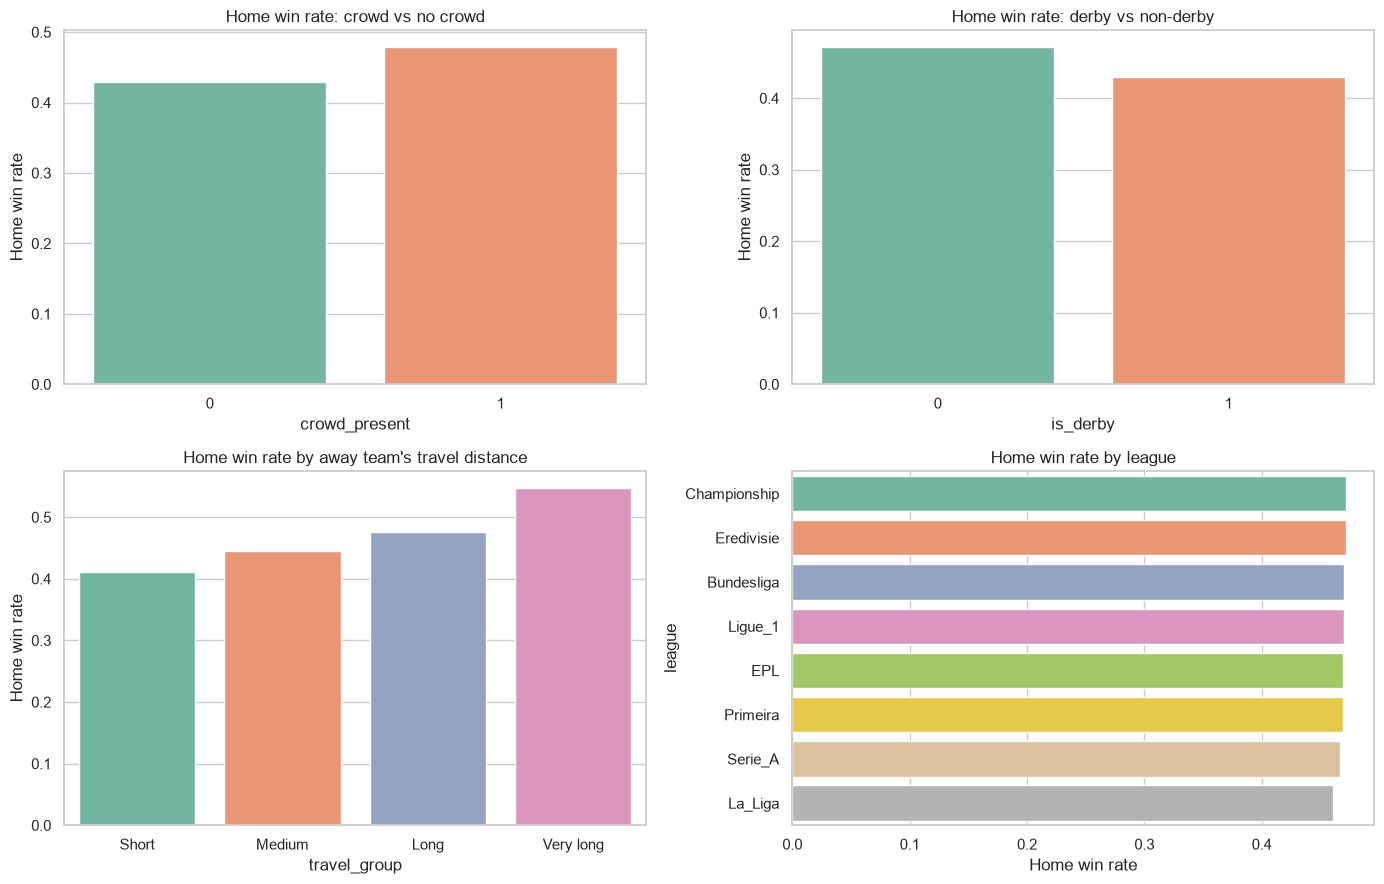

In [10]:
# Relationships with the target (bar plots)
# The question here is: which features change how often the home team wins?
df["home_win"] = (df[target] == "home_win").astype(int)   # helper column for plotting only

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.barplot(data=df, x="crowd_present", y="home_win", ax=axes[0, 0], palette="Set2", errorbar=None)
axes[0, 0].set_title("Home win rate: crowd vs no crowd")

sns.barplot(data=df, x="is_derby", y="home_win", ax=axes[0, 1], palette="Set2", errorbar=None)
axes[0, 1].set_title("Home win rate: derby vs non-derby")

df["travel_group"] = pd.qcut(df["travel_distance_km"], 4,
                             labels=["Short", "Medium", "Long", "Very long"])
sns.barplot(data=df, x="travel_group", y="home_win", ax=axes[1, 0], palette="Set2", errorbar=None)
axes[1, 0].set_title("Home win rate by away team's travel distance")

league_order = df.groupby("league")["home_win"].mean().sort_values(ascending=False).index
sns.barplot(data=df, y="league", x="home_win", order=league_order, ax=axes[1, 1], palette="Set2", errorbar=None)
axes[1, 1].set_title("Home win rate by league")

for ax in axes.flat:
    ax.set_ylabel(ax.get_ylabel().replace("home_win", "Home win rate"))
    ax.set_xlabel(ax.get_xlabel().replace("home_win", "Home win rate"))
plt.tight_layout()
plt.show()

**Observations**
- **Crowd:** home teams win ≈48% with a crowd vs ≈43% without. Fans add a few percentage points.
- **Derbies:** home win rate drops to ≈43%. Local rivals travel little and know the venue, so the advantage shrinks.
- **Travel distance:** the farther the away team travels, the more often the home team wins (≈41% for the shortest trips vs ≈55% for the longest).
- **League:** win rates are almost identical (46–47%), so `league` alone is a weak predictor.

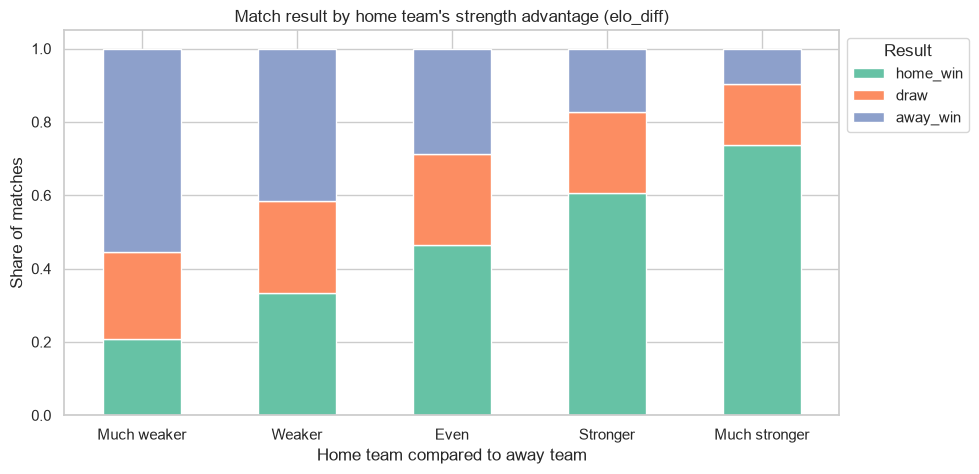

home_result,home_win,draw,away_win
elo_group,,,
Much weaker,0.208,0.238,0.554
Weaker,0.334,0.250,0.415
Even,0.465,0.246,0.289
Stronger,0.606,0.221,0.173
Much stronger,0.737,0.167,0.097


In [11]:
# Team strength vs result
df["elo_group"] = pd.cut(df["elo_diff"], [-700, -300, -100, 100, 300, 700],
                         labels=["Much weaker", "Weaker", "Even", "Stronger", "Much stronger"])

result_by_elo = pd.crosstab(df["elo_group"], df[target], normalize="index")[order]
result_by_elo.plot(kind="bar", stacked=True, figsize=(10, 5), color=sns.color_palette("Set2"))
plt.title("Match result by home team's strength advantage (elo_diff)")
plt.xlabel("Home team compared to away team"); plt.ylabel("Share of matches")
plt.xticks(rotation=0); plt.legend(title="Result", bbox_to_anchor=(1, 1))
plt.show()

result_by_elo.round(3)

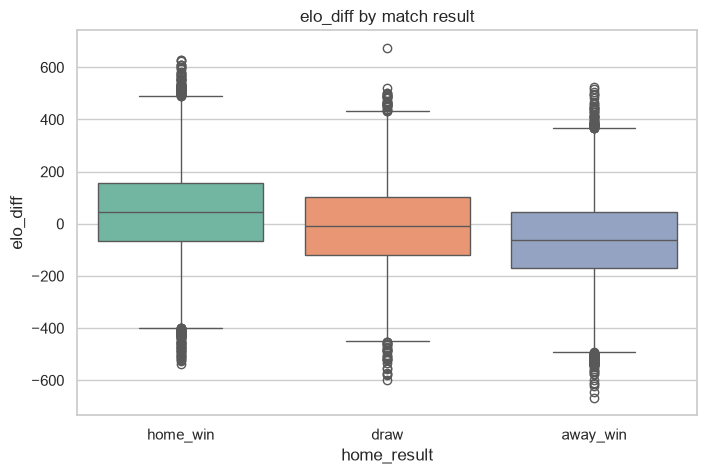

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x=target, y="elo_diff", order=order, palette="Set2")
plt.title("elo_diff by match result")
plt.show()

**Observations**
- `elo_diff` is the **strongest single predictor**. When the home team is much stronger they win ≈74% of the time. When much weaker, only ≈21%.
- Even when the teams are **evenly matched**, the home team still wins ≈47% vs ≈29% for the away team. That gap is home advantage itself.
- The draw share stays around 17–25% in every group. Draws don't depend clearly on any feature, so they will be the **hardest class** for the model.

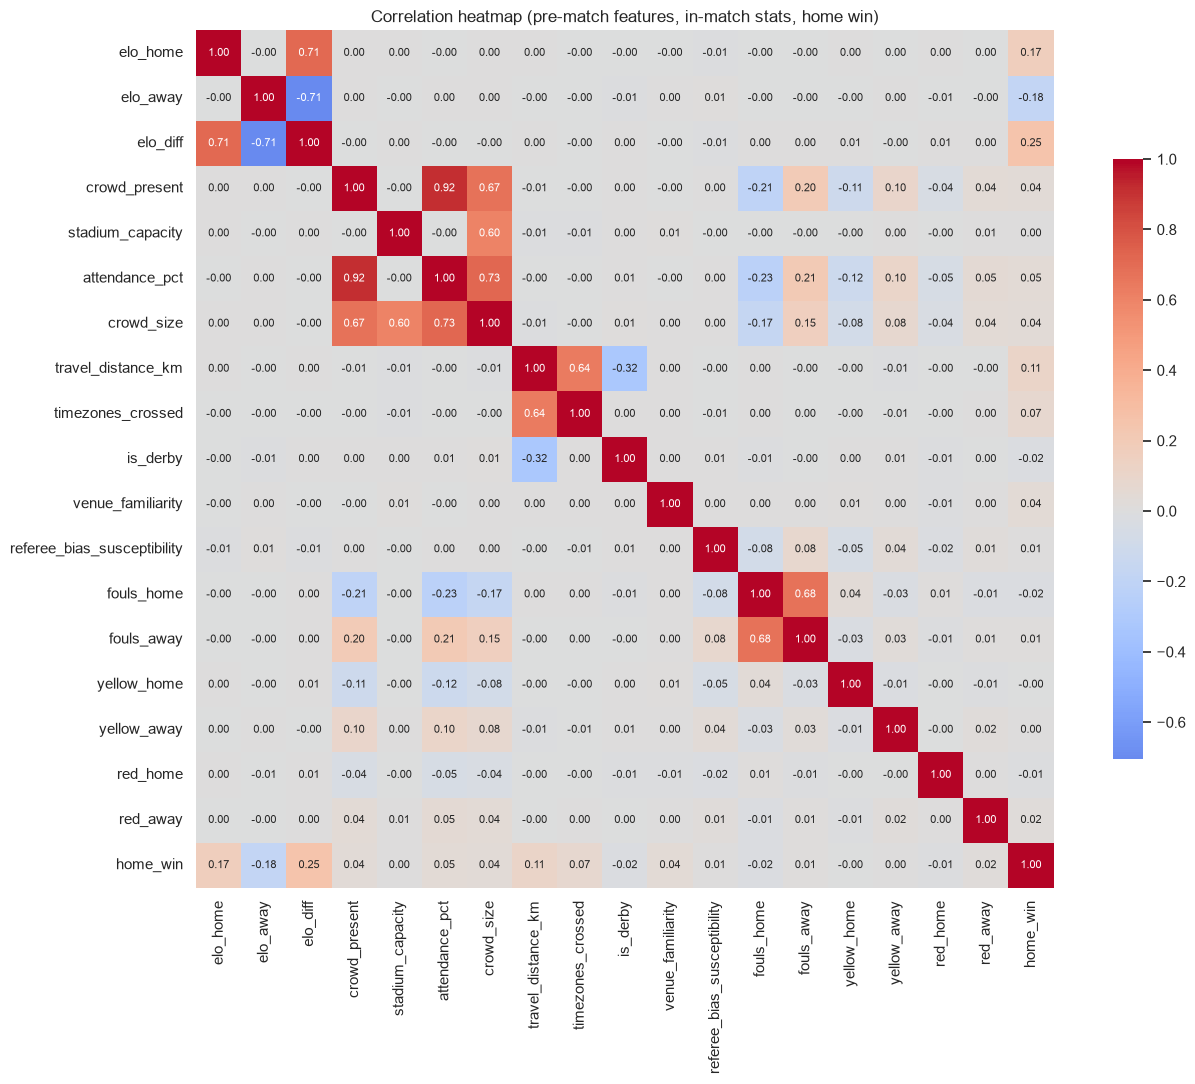

In [13]:
# Correlation heatmap
corr_cols = [c for c in pre_match_features if c != "league"] + in_match_stats + ["home_win"]
corr = df[corr_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7}, annot_kws={"size": 8})
plt.title("Correlation heatmap (pre-match features, in-match stats, home win)")
plt.tight_layout()
plt.show()

In [14]:
corr["home_win"].drop("home_win").sort_values(ascending=False).round(3)

elo_diff                       0.250
elo_home                       0.173
travel_distance_km             0.109
timezones_crossed              0.072
attendance_pct                 0.045
venue_familiarity              0.041
crowd_present                  0.040
crowd_size                     0.035
red_away                       0.015
fouls_away                     0.009
referee_bias_susceptibility    0.006
yellow_away                    0.004
stadium_capacity               0.002
yellow_home                   -0.001
red_home                      -0.009
fouls_home                    -0.016
is_derby                      -0.020
elo_away                      -0.180
Name: home_win, dtype: float64

**Observations**
- Strongest correlations with a home win: `elo_diff` (+0.25), `elo_home` (+0.17), `elo_away` (−0.18), then `travel_distance_km` (+0.11).
- Crowd features (`attendance_pct`, `crowd_present`, `crowd_size`) and `venue_familiarity` have small positive correlations (~0.04).
- **Redundant features:** `elo_diff` = `elo_home − elo_away`, and `crowd_size` ≈ `stadium_capacity × attendance_pct`. They are highly correlated with each other. That is fine for a Decision Tree (it just picks the most useful one), but worth knowing.
- Correlation only measures **linear** relationships. A Decision Tree can also capture non-linear effects and interactions (e.g. travel × crowd).

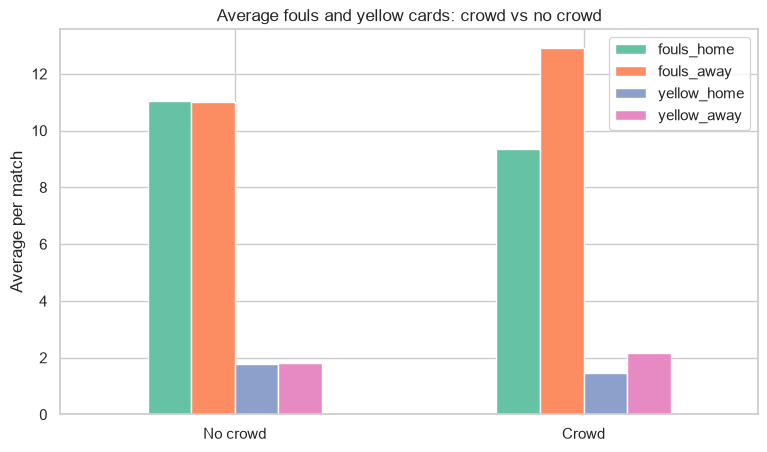

,fouls_home,fouls_away,yellow_home,yellow_away
No crowd,11.03,11.02,1.79,1.81
Crowd,9.36,12.92,1.45,2.17


In [15]:
# Crowd and referee decisions
fouls_by_crowd = df.groupby("crowd_present")[["fouls_home", "fouls_away", "yellow_home", "yellow_away"]].mean()
fouls_by_crowd.index = ["No crowd", "Crowd"]

fouls_by_crowd.plot(kind="bar", figsize=(9, 5), color=sns.color_palette("Set2"))
plt.title("Average fouls and yellow cards: crowd vs no crowd")
plt.ylabel("Average per match"); plt.xticks(rotation=0)
plt.show()

fouls_by_crowd.round(2)

**Observations**
- **Without a crowd**, home and away teams are called for about the same number of fouls (≈11 each).
- **With a crowd**, away teams get more fouls (≈12.9 vs ≈9.4) and more yellow cards. This suggests crowds influence referees, which is one mechanism behind home advantage.
- We still won't use these columns as model features, because they are only known during the match.

# **(3) Data Preprocessing**.

In [16]:
# Check missing values and duplicates
from sklearn.model_selection import train_test_split

data = df.copy()

print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

# Drop leakage columns and the ID
data = data.drop(["match_id", "goals_home", "goals_away", "home_goal_diff", "home_points"], axis=1)

print("Shape after dropping:", data.shape)

# One-hot encode league
data = pd.get_dummies(data, columns=["league"])

league_cols = [c for c in data.columns if c.startswith("league_")]
data[league_cols] = data[league_cols].astype(int)

print(data.columns.tolist())
data.head()

# Split features and target
X = data.drop("home_result", axis=1)
y = data["home_result"]

print("Features:", X.columns.tolist())
print("Target:", y.name)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)



Missing values: 0
Duplicate rows: 0
Shape after dropping: (50000, 23)
['elo_home', 'elo_away', 'elo_diff', 'crowd_present', 'stadium_capacity', 'attendance_pct', 'crowd_size', 'travel_distance_km', 'timezones_crossed', 'is_derby', 'venue_familiarity', 'referee_bias_susceptibility', 'fouls_home', 'fouls_away', 'yellow_home', 'yellow_away', 'red_home', 'red_away', 'home_result', 'home_win', 'travel_group', 'elo_group', 'league_Bundesliga', 'league_Championship', 'league_EPL', 'league_Eredivisie', 'league_La_Liga', 'league_Ligue_1', 'league_Primeira', 'league_Serie_A']
Features: ['elo_home', 'elo_away', 'elo_diff', 'crowd_present', 'stadium_capacity', 'attendance_pct', 'crowd_size', 'travel_distance_km', 'timezones_crossed', 'is_derby', 'venue_familiarity', 'referee_bias_susceptibility', 'fouls_home', 'fouls_away', 'yellow_home', 'yellow_away', 'red_home', 'red_away', 'home_win', 'travel_group', 'elo_group', 'league_Bundesliga', 'league_Championship', 'league_EPL', 'league_Eredivisie', 'l

# **(4) Model training**.

In [17]:
# Features and target
features = [
    "league",
    "elo_home",
    "elo_away",
    "elo_diff",
    "crowd_present",
    "stadium_capacity",
    "attendance_pct",
    "crowd_size",
    "travel_distance_km",
    "timezones_crossed",
    "is_derby",
    "venue_familiarity",
    "referee_bias_susceptibility"
]

X = df[features]
y = df["home_result"]

# Remove rows with missing target
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

# Identify categorical and numerical features
categorical_features = ["league"]
numerical_features = [col for col in features if col != "league"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Encode categorical features
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", "passthrough", numerical_features)
])

# Build, train the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)

# **(5) Model Evaluation**.

## Decision Tree: Impurity Measures

A Decision Tree picks each split by choosing the feature and threshold that make the child nodes as **pure** as possible, meaning each node holds mostly one class.

Below, we compute the measures the tree uses to judge purity: **Gini impurity**, **entropy**, and **information gain**. Then we look at how a leaf makes its prediction and check our results against scikit-learn.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

In [19]:
from sklearn.dummy import DummyClassifier

labels = ["home_win", "draw", "away_win"]

# BaseLine
We compare the model with a simple baseline that always predicts the most common result (home win). The model is only useful if it beats this.

In [20]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_base = baseline.predict(X_test)

In [21]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

# Decision Tree results
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Baseline vs Decision Tree
print("Baseline accuracy:", accuracy_score(y_test, y_base))
print("Tree accuracy:", accuracy_score(y_test, y_pred))
print("Baseline macro F1:", f1_score(y_test, y_base, average="macro", zero_division=0))
print("Tree macro F1:", f1_score(y_test, y_pred, average="macro"))

[[1533  499  906]
 [ 913  410 1054]
 [1214  713 2758]]
              precision    recall  f1-score   support

    away_win       0.42      0.52      0.46      2938
        draw       0.25      0.17      0.21      2377
    home_win       0.58      0.59      0.59      4685

    accuracy                           0.47     10000
   macro avg       0.42      0.43      0.42     10000
weighted avg       0.46      0.47      0.46     10000

Baseline accuracy: 0.4685
Tree accuracy: 0.4701
Baseline macro F1: 0.21268868459879697
Tree macro F1: 0.41878627415308395


### Class proportions
Each impurity measure is built on $p_i$, the share of samples from class $i$ in a node:

$$p_i = \frac{\text{samples of class } i}{\text{total samples in the node}}$$

In [22]:
def proportions(y):
    return pd.Series(y).value_counts(normalize=True)

proportions(y_train)

home_result
home_win    0.468525
away_win    0.293775
draw        0.237700
Name: proportion, dtype: float64

### 1. Gini impurity
Gini measures how mixed a node is. $G = 0$ means every sample belongs to one class, and it gets bigger as the classes mix more evenly. It's the default criterion in scikit-learn.

$$G = 1 - \sum_{i=1}^{C} p_i^2$$

In [23]:
def gini(y):
    p = proportions(y)
    return 1 - (p ** 2).sum()

print("Gini at the root node:", round(gini(y_train), 3))

Gini at the root node: 0.638


### 2. Entropy
Entropy measures the uncertainty in a node. $H = 0$ means the node is pure. It's used when `criterion="entropy"`.

$$H = -\sum_{i=1}^{C} p_i \log_2(p_i)$$

In [24]:
from scipy.stats import entropy

def node_entropy(y):
    return entropy(proportions(y), base=2)

print("Entropy at the root node:", round(node_entropy(y_train), 3))

Entropy at the root node: 1.524


### 3. Information gain
Information gain is how much a split lowers the entropy. Each child node is weighted by its share of the samples, and the tree picks the split with the highest gain.

$$IG = H_{parent} - \sum_{j=1}^{k} \frac{N_j}{N} H_j$$

In [25]:
def information_gain(parent, children):
    N = len(parent)
    weighted = sum(len(child) / N * node_entropy(child) for child in children)
    return node_entropy(parent) - weighted

# Example split: H = home win, A = away win, D = draw
parent = ["H"]*5 + ["A"]*3 + ["D"]*2
left   = ["H"]*4 + ["A"]*1
right  = ["H"]*1 + ["A"]*2 + ["D"]*2

print("Information gain:", round(information_gain(parent, [left, right]), 3))  # 0.364

Information gain: 0.364


### Weighted Gini of a split
This is the same weighting idea, using Gini instead of entropy. A lower value means a better split.

$$G_{split} = \sum_{j=1}^{k} \frac{N_j}{N} G_j$$

In [26]:
def gini_split(parent, children):
    N = len(parent)
    return sum(len(child) / N * gini(child) for child in children)

print("Gini of the split:", round(gini_split(parent, [left, right]), 3))  # 0.48

Gini of the split: 0.48


### 4. Prediction at a leaf
When splitting stops, a leaf predicts the class that appears most often among its samples.

$$\hat{y} = \arg\max_i \; p_i$$

In [27]:
def leaf_prediction(y):
    return proportions(y).idxmax()

print("Left leaf predicts:", leaf_prediction(left))  # H

Left leaf predicts: H


### Check against scikit-learn
sklearn stores the impurity of every node in a trained tree. The value at the root should match our own Gini of `y_train`.

In [28]:
print("Our Gini:    ", round(gini(y_train), 3))
print("sklearn Gini:", round(model[-1].tree_.impurity[0], 3))

Our Gini:     0.638
sklearn Gini: 0.667


# **(7) Conclusion and Key Insights**

### How well did the model do?

| | Baseline (always "home win") | Decision Tree |
|---|---|---|
| Accuracy | 46.9% | 47.0% |
| Macro F1-score | 0.21 | 0.42 |

- **Accuracy barely changed.** On accuracy alone, the tree is no better than always guessing "home win".
- **But the tree is much more useful.** The baseline never predicts a draw or an away win. The tree predicts all three results, which is why the macro F1-score doubled from 0.21 to 0.42.
- **Why accuracy did not go up:** we used `class_weight="balanced"`, which makes the tree treat draws and away wins as just as important as home wins. It gives up some easy "home win" guesses in order to catch the other results.

### Which results are easy and hard to predict?
- **Home wins are the easiest** (F1 = 0.59): the tree correctly finds 59% of them.
- **Away wins are in the middle** (F1 = 0.46): it finds 52% of them.
- **Draws are the hardest** (F1 = 0.21): it finds only 17% of them. This matches the EDA, where the share of draws stayed around 17% to 25% whatever the team strength, so no feature clearly signals a draw.

### Why our Gini (0.638) is different from sklearn's (0.667)
This is not a bug. Because of `class_weight="balanced"`, sklearn gives every class the same total weight, so the root node looks like one third of each class:

$$G = 1 - 3 \times \left(\tfrac{1}{3}\right)^2 = 0.667$$

Our function uses the real class shares (47%, 29%, 24%), which gives 0.638.

### So is home advantage real, or just team strength?
**Both matter, but home advantage is real.**
- **Team strength matters most:** a much stronger home team wins 74% of its matches, and a much weaker one wins only 21%.
- **Home advantage still exists when teams are equal:** evenly matched home teams win 46.5% of matches, compared with 28.9% for away teams.
- **Crowds help:** home teams win about 48% of matches with fans, compared with 43% without.
- **Referees seem to be affected by crowds:** with no crowd, both teams get about 11 fouls. With a crowd, away teams get about 12.9 fouls compared with 9.4 for the home team.
- **Travel matters:** the home win rate rises from about 41% for the shortest away trips to about 55% for the longest.
- **Derbies shrink the advantage** (about 43% home wins), because the away team barely travels and already knows the venue.

### Limitations
- Football is noisy: pre-match information alone cannot predict results reliably, which is why accuracy stays near 47%.
- The tree is kept small (`max_depth=5`) so it is easy to read, which also limits how much it can learn.
- These are patterns in the data, not proof of cause and effect.

### Bottom line
Team strength explains most match results, but playing at home gives a real extra edge, partly through the crowd, referee decisions, and away-team travel.